# CSCI 4150 · Meeting 10 Starter Notebook
## Neural Networks: Learn + Reverse Engineer

**Central question:** How can a system learn representations we did not explicitly define?

This notebook uses a small synthetic dataset so you can inspect how a neural network changes behavior when you change architecture, training, and data conditions. The goal is not to build the best model. The goal is to collect evidence about system behavior.

Use this notebook with the Meeting 10 handout.

## What to save as evidence

For each experiment, record:

| Change made | Observed result | Failure / pattern | Interpretation |
|---|---|---|---|
| baseline / architecture / training / data change | accuracy, loss, plot, errors | underfit / overfit / data issue / evaluation issue / semantic mismatch | what the evidence means |

A justified **reject** or **defer** decision is valid evidence.

In [ ]:
# Imports
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

from sklearn.datasets import make_moons, make_blobs
from sklearn.model_selection import train_test_split
from sklearn.preprocessing import StandardScaler
from sklearn.neural_network import MLPClassifier
from sklearn.metrics import accuracy_score, confusion_matrix, classification_report

RANDOM_STATE = 4150
np.random.seed(RANDOM_STATE)

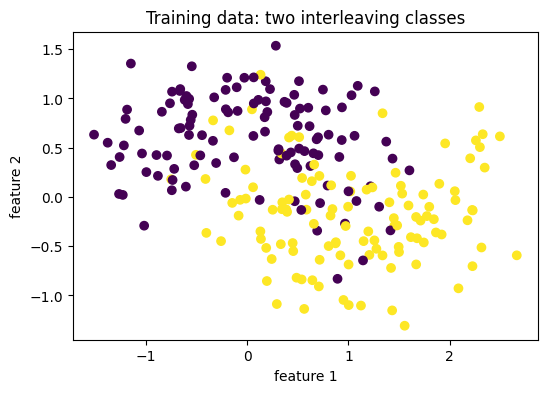

In [ ]:
# Create a small dataset with a non-linear pattern
# Try changing noise from 0.05 to 0.35 later.

X, y = make_moons(n_samples=350, noise=0.35, random_state=RANDOM_STATE)

X_train, X_test, y_train, y_test = train_test_split(
    X, y, test_size=0.35, random_state=RANDOM_STATE, stratify=y
)

scaler = StandardScaler()
X_train_scaled = scaler.fit_transform(X_train)
X_test_scaled = scaler.transform(X_test)

plt.figure(figsize=(6, 4))
plt.scatter(X_train[:, 0], X_train[:, 1], c=y_train)
plt.title("Training data: two interleaving classes")
plt.xlabel("feature 1")
plt.ylabel("feature 2")
plt.show()

In [ ]:
def train_model(hidden_layer_sizes=(4,), activation="relu", alpha=0.0001, max_iter=1000):
    """Train a simple neural network classifier and return model + metrics."""
    model = MLPClassifier(
        hidden_layer_sizes=hidden_layer_sizes,
        activation=activation,
        alpha=alpha,
        max_iter=max_iter,
        random_state=RANDOM_STATE
    )
    model.fit(X_train_scaled, y_train)

    train_pred = model.predict(X_train_scaled)
    test_pred = model.predict(X_test_scaled)

    results = {
        "hidden_layer_sizes": hidden_layer_sizes,
        "activation": activation,
        "alpha": alpha,
        "iterations": model.n_iter_,
        "train_accuracy": accuracy_score(y_train, train_pred),
        "test_accuracy": accuracy_score(y_test, test_pred),
        "train_loss_final": model.loss_,
    }
    return model, results

def plot_decision_boundary(model, title="Decision boundary"):
    """Plot the model's decision regions so behavior is visible."""
    x_min, x_max = X[:, 0].min() - 0.6, X[:, 0].max() + 0.6
    y_min, y_max = X[:, 1].min() - 0.6, X[:, 1].max() + 0.6
    xx, yy = np.meshgrid(
        np.linspace(x_min, x_max, 220),
        np.linspace(y_min, y_max, 220)
    )

    grid = np.c_[xx.ravel(), yy.ravel()]
    grid_scaled = scaler.transform(grid)
    Z = model.predict(grid_scaled).reshape(xx.shape)

    plt.figure(figsize=(6, 4))
    plt.contourf(xx, yy, Z, alpha=0.25)
    plt.scatter(X_test[:, 0], X_test[:, 1], c=y_test, edgecolor="k")
    plt.title(title)
    plt.xlabel("feature 1")
    plt.ylabel("feature 2")
    plt.show()

def summarize(model, results):
    print(pd.Series(results))
    print("\nConfusion matrix on test set:")
    print(confusion_matrix(y_test, model.predict(X_test_scaled)))
    print("\nClassification report:")
    print(classification_report(y_test, model.predict(X_test_scaled)))

## Baseline model

Start with a small network. Ask:

- Is this too simple?
- What does the decision boundary show?
- Does test performance match training performance?

hidden_layer_sizes        (4,)
activation                relu
alpha                   0.0001
iterations                 454
train_accuracy        0.859031
test_accuracy         0.829268
train_loss_final      0.382283
dtype: object

Confusion matrix on test set:
[[52 10]
 [11 50]]

Classification report:
              precision    recall  f1-score   support

           0       0.83      0.84      0.83        62
           1       0.83      0.82      0.83        61

    accuracy                           0.83       123
   macro avg       0.83      0.83      0.83       123
weighted avg       0.83      0.83      0.83       123



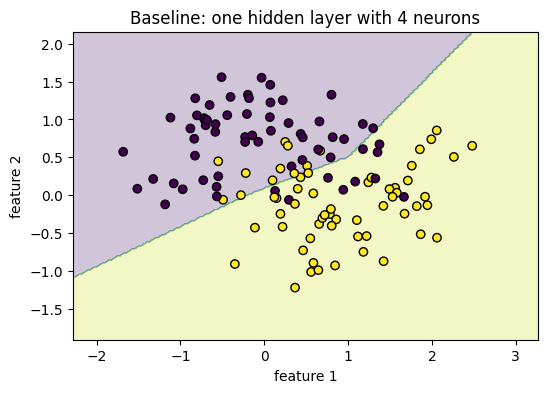

In [ ]:
baseline_model, baseline_results = train_model(hidden_layer_sizes=(4,), activation="relu", alpha=0.0001)
summarize(baseline_model, baseline_results)
plot_decision_boundary(baseline_model, "Baseline: one hidden layer with 4 neurons")

## Experiment 1 — Change architecture

Change **one variable**. For example:

- Try `(1,)` for a very small network.
- Try `(8,)`.
- Try `(16, 16)`.
- Try `(32, 32, 32)`.

Record whether the model looks underfit, useful, or overfit.

hidden_layer_sizes    (16, 16)
activation                relu
alpha                   0.0001
iterations                 238
train_accuracy        0.854626
test_accuracy         0.829268
train_loss_final      0.369633
dtype: object

Confusion matrix on test set:
[[54  8]
 [13 48]]

Classification report:
              precision    recall  f1-score   support

           0       0.81      0.87      0.84        62
           1       0.86      0.79      0.82        61

    accuracy                           0.83       123
   macro avg       0.83      0.83      0.83       123
weighted avg       0.83      0.83      0.83       123



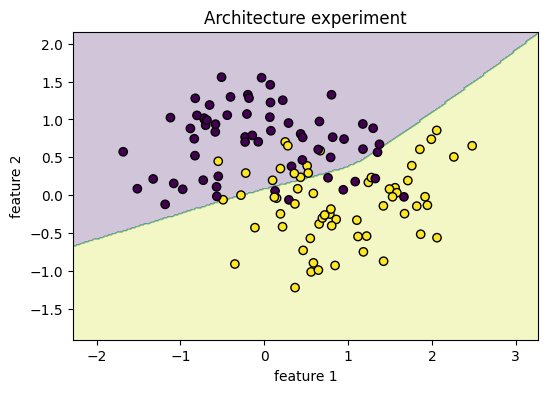

In [ ]:
# TODO: change hidden_layer_sizes and rerun
architecture_model, architecture_results = train_model(
    hidden_layer_sizes=(16, 16),
    activation="relu",
    alpha=0.0001
)

summarize(architecture_model, architecture_results)
plot_decision_boundary(architecture_model, "Architecture experiment")

## Experiment 2 — Change regularization

`alpha` controls regularization. Higher values discourage very complex fits.

Try:
- `alpha=0.0001`
- `alpha=0.01`
- `alpha=0.1`
- `alpha=1.0`

Ask: does regularization help generalization or make the model too simple?

hidden_layer_sizes    (32, 32)
activation                relu
alpha                     0.01
iterations                 369
train_accuracy        0.867841
test_accuracy         0.886179
train_loss_final      0.338508
dtype: object

Confusion matrix on test set:
[[57  5]
 [ 9 52]]

Classification report:
              precision    recall  f1-score   support

           0       0.86      0.92      0.89        62
           1       0.91      0.85      0.88        61

    accuracy                           0.89       123
   macro avg       0.89      0.89      0.89       123
weighted avg       0.89      0.89      0.89       123



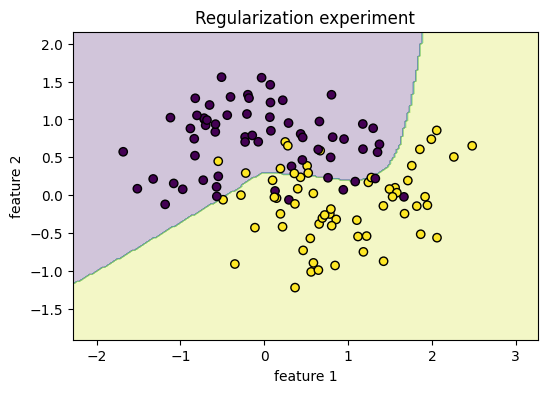

In [ ]:
# TODO: change alpha and rerun
regularized_model, regularized_results = train_model(
    hidden_layer_sizes=(32, 32),
    activation="relu",
    alpha=0.01
)

summarize(regularized_model, regularized_results)
plot_decision_boundary(regularized_model, "Regularization experiment")

## Experiment 3 — Change data noise

Go back to the data-creation cell and change the `noise` value.

Try:
- `noise=0.05`
- `noise=0.18`
- `noise=0.35`

Then rerun the notebook. Ask:

- Does more data noise make the boundary less reliable?
- Does the same architecture behave differently?
- What would this mean for a project with messy real-world data?

In [ ]:
# Evidence summary table
evidence = pd.DataFrame([
    {
        "change_made": "baseline: hidden_layer_sizes=(4,)",
        "observed_result": f"train={baseline_results['train_accuracy']:.3f}, test={baseline_results['test_accuracy']:.3f}",
        "failure_or_pattern": "TBD",
        "interpretation": "TBD"
    },
    {
        "change_made": f"architecture: {architecture_results['hidden_layer_sizes']}",
        "observed_result": f"train={architecture_results['train_accuracy']:.3f}, test={architecture_results['test_accuracy']:.3f}",
        "failure_or_pattern": "TBD",
        "interpretation": "TBD"
    },
    {
        "change_made": f"regularization alpha={regularized_results['alpha']}",
        "observed_result": f"train={regularized_results['train_accuracy']:.3f}, test={regularized_results['test_accuracy']:.3f}",
        "failure_or_pattern": "TBD",
        "interpretation": "TBD"
    },
])

evidence

,change_made,observed_result,failure_or_pattern,interpretation
0,"baseline: hidden_layer_sizes=(4,)","train=0.859, test=0.829",TBD,TBD
1,"architecture: (16, 16)","train=0.855, test=0.829",TBD,TBD
2,regularization alpha=0.01,"train=0.868, test=0.886",TBD,TBD


## Project transfer: plan Friday's experiment

Answer these before you leave:

1. What would the input be in your project?
2. What output or behavior would you test?
3. What data/evidence do you already have?
4. What would count as success?
5. What would count as failure?
6. Based on today, do you expect to **adopt**, **modify**, **reject**, or **defer** a neural approach? Why?

In [ ]:
project_plan = {
    "project_hypothesis": "",
    "input": "",
    "output_or_behavior": "",
    "evidence_available": "",
    "success_criterion": "",
    "failure_criterion": "",
    "expected_decision": "adopt / modify / reject / defer",
    "why": ""
}

project_plan

{'project_hypothesis': '',
 'input': '',
 'output_or_behavior': '',
 'evidence_available': '',
 'success_criterion': '',
 'failure_criterion': '',
 'expected_decision': 'adopt / modify / reject / defer',
 'why': ''}